# 26. Number of training bearings needed for a RUL floor

Notebooks 22 to 25 measured how far this project's attribution numbers travel: an exact bearing-level permutation null (nb22), a unit-count power curve on each rig (nb23, nb24), and a reliability layer whose between-unit interval turned out to be [0 %, 100 %] (nb25). The one positive remaining-life result, RUL reported as a floor ("at least n minutes") and not as a point estimate, has not been through any of this.

Two standing open items ask for the same measurement. Notebook 17's is the more specific one, because it corrected its own main result. It found that at q0.10 only 6 of 11 units individually clear 90 % safety, and that Bearing2_4, the 42-minute unit and the shortest life in the set, is 18 % safe. It noted that a floor is a per-unit promise, and that reporting it as a median over units understates how often it is broken on the unit in front of you. The equivalent curve for the floor's per-unit safety was left unmeasured, and it decides whether "at least n minutes" can be said to an engineer at all.

So the question is what share of bearings the promise holds for, and whether a larger training fleet raises that share.

`src/build_floor_curve.py` measures it. For each training-fleet size n, we draw subsets of the 15 bearings, fit notebook 16's forest on those units only, and score every held-out unit on notebook 17's pair. Safety is the share of post-alarm minutes where the floor does not overstate the life left. Give-up is the median share of remaining life the floor gives up to reach that safety.

Both controls from the standing rule run alongside, because safety on its own is easy to reach: a floor of zero minutes is 100 % safe and gives up everything. The forest therefore has to beat the controls on the pair, against:

- a prior floor: the same quantile of the training fleet's own post-alarm lifetime distribution, ignoring the features entirely. This is the physically incapable control, since it cannot know anything about the unit in front of it.
- a permuted forest: the identical model fitted after shuffling RUL across all training rows, which destroys the feature-to-lifetime map. This is the null control.

n = 14 is exhaustive (15 subsets, one per omitted bearing), so the right-hand end of every curve is notebook 17's leave-one-bearing-out result exactly and not approximately. That is the build's own correctness check, and it is the first thing printed.

In [1]:
import pathlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

OUT = pathlib.Path("../data/processed")
d = pd.read_csv(OUT / "floor_curve.csv")      # src/build_floor_curve.py, 32.8 min
RACE = ("OR", "IR")
Q = 0.10                                      # notebook 16's setting, kept by nb17
SCHEMES = [("forest", "notebook 16's floor"),
           ("prior", "control: the training fleet's own lifetime quantile"),
           ("permuted", "control: the same forest on shuffled lifetimes")]

C_BLUE, C_ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, BASE, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
# one hue, light -> dark: fleet size is a magnitude, not an identity
RAMP = ["#a8c8ee", "#5e9ae0", "#2a78d6", "#1b4f8f"]
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "text.color": INK, "axes.titlecolor": INK, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": BASE,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "legend.frameon": False,
})
SCOLOR = {"forest": C_BLUE, "prior": MUTED, "permuted": C_ORANGE}
FRONT_N = [4, 7, 11, 14]                      # fleet sizes drawn on the frontier

base = d[d["q"] == Q]
rep = base[(base["n"] == 14) & (base["scheme"] == "forest")]
rep_race = rep[rep["fault"].isin(RACE)]
print(f"floor_curve.csv: {len(d)} rows, fleets of n = {d['n'].min()}-{d['n'].max()} bearings, "
      f"up to {d['subset'].nunique()} per size, quantiles {sorted(d['q'].unique())}")
print("\nreproduction at n=14 (leave-one-bearing-out, the 11 race units, q0.10):")
print(f"  median safety   {rep_race['safety'].median():.0%}    (notebook 17: 91 %)")
print(f"  median give-up  {rep_race['giveup'].median():.0%}    (notebook 17: 63 %)")
print(f"  units clearing 90 % safety  {(rep_race['safety'] >= 0.90).sum()}/{len(rep_race)}"
      f"     (notebook 17: 6/11)")
print(f"  over all 15 units: {(rep['safety'] >= 0.90).sum()}/{len(rep)} clear 90 %")

CURVE = []
for n, g in base.groupby("n"):
    row = dict(n=n, rows=g["n_rows"].mean())
    for sc, _ in SCHEMES:
        s = g[g["scheme"] == sc]
        row[f"{sc}_clear"] = float((s["safety"] >= 0.90).mean())
        row[f"{sc}_safety"] = float(s["safety"].median())
        row[f"{sc}_giveup"] = float(s["giveup"].median())
    CURVE.append(row)
C = pd.DataFrame(CURVE)
print(f"\n{'fleet':>5} {'rows':>6} | {'forest':>26} | {'prior':>17} | {'permuted':>17}")
print(f"{'':>5} {'':>6} | {'clear90':>9}{'safety':>8}{'give-up':>9} | {'clear90':>8}{'safety':>9}"
      f" | {'clear90':>8}{'safety':>9}")
for _, r in C.iterrows():
    print(f"{r['n']:5.0f} {r['rows']:6.0f} | {r['forest_clear']:9.1%}{r['forest_safety']:8.1%}"
          f"{r['forest_giveup']:9.1%} | {r['prior_clear']:8.1%}{r['prior_safety']:9.1%}"
          f" | {r['permuted_clear']:8.1%}{r['permuted_safety']:9.1%}")

floor_curve.csv: 25320 rows, fleets of n = 4-14 bearings, up to 16 per size, quantiles [np.float64(0.02), np.float64(0.06), np.float64(0.1), np.float64(0.14), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5)]

reproduction at n=14 (leave-one-bearing-out, the 11 race units, q0.10):
  median safety   91%    (notebook 17: 91 %)
  median give-up  63%    (notebook 17: 63 %)
  units clearing 90 % safety  6/11     (notebook 17: 6/11)
  over all 15 units: 8/15 clear 90 %

fleet   rows |                     forest |             prior |          permuted
             |   clear90  safety  give-up |  clear90   safety |  clear90   safety
    4   2895 |     44.9%   80.5%    49.6% |    29.0%    80.5% |     6.2%     6.4%
    5   3466 |     37.5%   69.6%    34.5% |    38.8%    86.3% |     5.6%    11.7%
    6   4335 |     40.3%   80.2%    41.1% |    23.6%    80.4% |     1.4%     8.2%
    7   4379 |     34.4%   66.8%    41.2% |    24.2%    81.0% |     2.3%    11.5%
    8   4796 |     41

The harness reproduces notebook 17 on all three numbers at once: 91 % median safety, 63 % median give-up, and 6 of 11 race units clearing 90 %. The right-hand end of every curve below is therefore that result and not an approximation of it. Over all fifteen units it is 8 of 15.

The table already answers the question, and it is worth reading before the figure. The forest's 90 %-safe share starts at 44.9 % on fleets of four bearings and ends at 53.3 % on fleets of fourteen. That is the whole gain from nine extra bearings.

## Fleet size and the per-unit promise

The left panel is the measurement the two open items asked for: the share of held-out bearings whose floor is 90 % safe, against the number of bearings the forest was trained on, with both controls on the same axes.

The right panel asks the same question a second way, because a single operating point can move for reasons unrelated to skill. Sweeping the quantile traces the whole safety / give-up frontier. A training fleet that really teaches the model something has to push that frontier outward, with more safety at the same give-up or the same safety at less give-up. A curve that only slides along its own frontier has gained nothing.

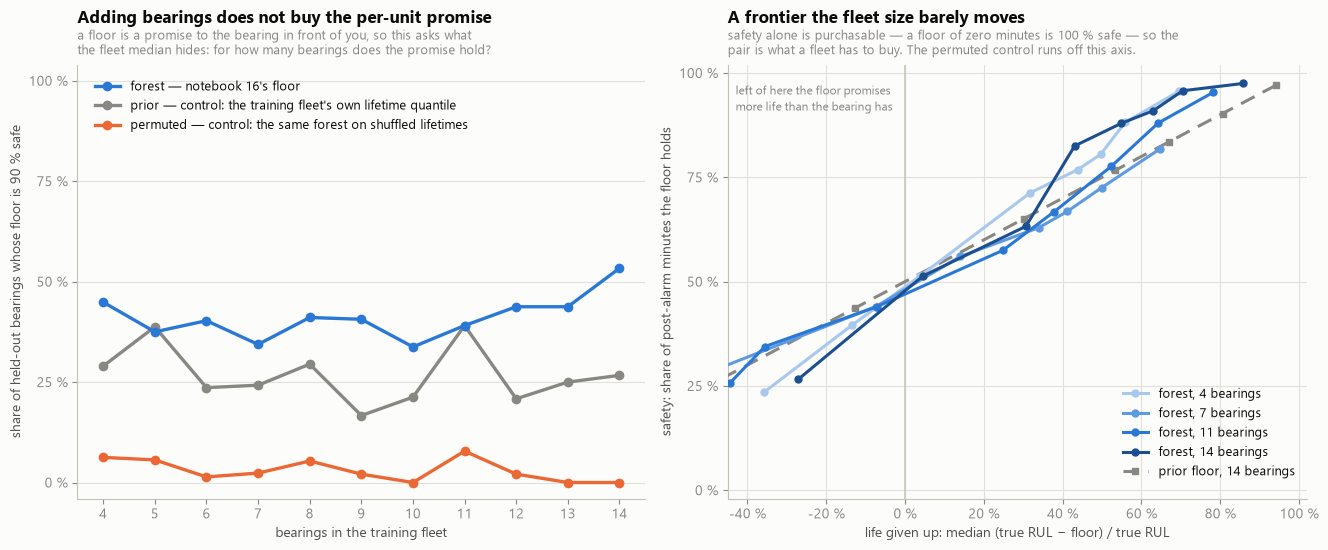

Spearman against fleet size, over the eleven fleet sizes:
  forest    clear  rho = +0.323  p = 0.332   range 34% to 53%
  forest    safety rho = +0.382  p = 0.247   range 62% to 91%
  prior     clear  rho = -0.191  p = 0.574   range 17% to 39%
  prior     safety rho = +0.536  p = 0.089   range 80% to 87%
  permuted  clear  rho = -0.566  p = 0.070   range 0% to 8%
  permuted  safety rho = +0.782  p = 0.004   range 6% to 29%

does the forest beat the prior at a give-up it also pays?
  n= 4: forest 49.6% give-up -> 80.5% safe, 44.9% clear  ||  prior q0.14 45.1% give-up -> 72.0% safe, 17.6% clear
  n= 5: forest 34.5% give-up -> 69.6% safe, 37.5% clear  ||  prior q0.30  2.6% give-up -> 51.3% safe, 13.8% clear
  n= 6: forest 41.1% give-up -> 80.2% safe, 40.3% clear  ||  prior q0.20 18.1% give-up -> 59.0% safe,  9.7% clear
  n= 7: forest 41.2% give-up -> 66.8% safe, 34.4% clear  ||  prior q0.20 18.0% give-up -> 59.0% safe,  8.6% clear
  n= 8: forest 50.2% give-up -> 73.0% safe, 41.1% clear  |

In [2]:
fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.4, 5.6),
                               gridspec_kw=dict(width_ratios=[1, 1.02]))

for sc, note in SCHEMES:
    axa.plot(C["n"], 100 * C[f"{sc}_clear"], color=SCOLOR[sc], lw=2.4, marker="o", ms=6,
             zorder=4 if sc == "forest" else 3, label=f"{sc} — {note}")
axa.set_xticks(C["n"])
axa.set_xlabel("bearings in the training fleet")
axa.set_ylabel("share of held-out bearings whose floor is 90 % safe")
axa.set_ylim(-4, 104)
axa.set_yticks(range(0, 101, 25))
axa.set_yticklabels([f"{v} %" for v in range(0, 101, 25)])
axa.set_title("Adding bearings does not buy the per-unit promise", loc="left",
              fontsize=12.5, fontweight="bold", pad=30)
axa.annotate("a floor is a promise to the bearing in front of you, so this asks what\n"
             "the fleet median hides: for how many bearings does the promise hold?",
             xy=(0, 1.015), xycoords="axes fraction", fontsize=9.3, color=MUTED, va="bottom")
axa.legend(loc="upper left", fontsize=9.2, bbox_to_anchor=(0.01, 0.99))

for i, nn in enumerate(FRONT_N):
    g = d[(d["n"] == nn) & (d["scheme"] == "forest")]
    p = g.groupby("q").agg(s=("safety", "median"), gu=("giveup", "median")).reset_index()
    axb.plot(100 * p["gu"], 100 * p["s"], color=RAMP[i], lw=2.2, marker="o", ms=5, zorder=4,
             label=f"forest, {nn} bearings")
g = d[(d["n"] == 14) & (d["scheme"] == "prior")]
p = g.groupby("q").agg(s=("safety", "median"), gu=("giveup", "median")).reset_index()
axb.plot(100 * p["gu"], 100 * p["s"], color=MUTED, lw=2.2, ls=(0, (5, 3)), marker="s", ms=5,
         zorder=3, label="prior floor, 14 bearings")
axb.axvline(0, color=BASE, lw=1.1, zorder=2)
axb.annotate("left of here the floor promises\nmore life than the bearing has",
             (-43, 91), fontsize=8.8, color=MUTED, ha="left", linespacing=1.4)
axb.set_xlim(-45, 102)
axb.set_ylim(-2, 102)
axb.set_xticks(range(-40, 101, 20))
axb.set_xticklabels([f"{v} %" for v in range(-40, 101, 20)])
axb.set_yticks(range(0, 101, 25))
axb.set_yticklabels([f"{v} %" for v in range(0, 101, 25)])
axb.set_xlabel("life given up: median (true RUL − floor) / true RUL")
axb.set_ylabel("safety: share of post-alarm minutes the floor holds")
axb.set_title("A frontier the fleet size barely moves", loc="left", fontsize=12.5,
              fontweight="bold", pad=30)
axb.annotate("safety alone is purchasable — a floor of zero minutes is 100 % safe — so the\n"
             "pair is what a fleet has to buy. The permuted control runs off this axis.",
             xy=(0, 1.015), xycoords="axes fraction", fontsize=9.3, color=MUTED, va="bottom")
axb.legend(loc="lower right", fontsize=9.2, bbox_to_anchor=(1.0, 0.02))
axa.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print("Spearman against fleet size, over the eleven fleet sizes:")
for sc, _ in SCHEMES:
    for t in ("clear", "safety"):
        rho, p = spearmanr(C["n"], C[f"{sc}_{t}"])
        print(f"  {sc:9s} {t:6s} rho = {rho:+.3f}  p = {p:.3f}   range "
              f"{C[f'{sc}_{t}'].min():.0%} to {C[f'{sc}_{t}'].max():.0%}")

print("\ndoes the forest beat the prior at a give-up it also pays?")
for nn in sorted(d["n"].unique()):
    g = d[d["n"] == nn]
    f10 = g[(g["scheme"] == "forest") & (g["q"] == Q)]
    tgt = f10["giveup"].median()
    cand = [(q, x["giveup"].median(), x["safety"].median(), (x["safety"] >= 0.90).mean())
            for q in sorted(d["q"].unique())
            for x in [g[(g["scheme"] == "prior") & (g["q"] == q)]]
            if x["giveup"].median() <= tgt]
    if cand:
        q, gu, sa, cl = max(cand, key=lambda c: c[1])
        print(f"  n={nn:2d}: forest {tgt:5.1%} give-up -> {f10['safety'].median():5.1%} safe, "
              f"{(f10['safety'] >= 0.90).mean():5.1%} clear  ||  prior q{q:.2f} {gu:5.1%} "
              f"give-up -> {sa:5.1%} safe, {cl:5.1%} clear")

sub = (base[base["scheme"] == "forest"].groupby(["n", "subset"])
       .agg(safety=("safety", "median"),
            clear=("safety", lambda s: float((s >= 0.90).mean())),
            rows=("n_rows", "first")).reset_index())
print("\nbearings or snapshots? (the nb24 confound check, one point per fleet)")
for t in ("safety", "clear"):
    print(f"  {t:6s} vs bearings  rho = {spearmanr(sub['n'], sub[t])[0]:+.3f}"
          f"   vs snapshots rho = {spearmanr(sub['rows'], sub[t])[0]:+.3f}")
    for nn in (8, 10, 12):
        s = sub[sub["n"] == nn]
        print(f"      at fixed n={nn}: vs snapshots rho = {spearmanr(s['rows'], s[t])[0]:+.3f}")

More bearings do not raise the share of bearings with a 90 %-safe floor. From 4 to 14 units, a fleet three and a half times larger, that share moves from 44.9 % to 53.3 %, with rho = +0.323, p = 0.33 over the eleven fleet sizes and excursions down to 33.8 % on the way. Median safety behaves the same way (+0.382, p = 0.25). Neither trend is distinguishable from noise, and the right panel shows that this is not an artefact of one operating point: the whole safety–give-up frontier for four bearings sits almost on top of the frontier for fourteen. The larger fleet moves the model along a frontier it already had and does not improve the promise.

The floor still carries information, and both controls show it. The permuted forest collapses to 0–7.8 % of bearings clearing 90 %, reaching exactly 0 % at the two largest fleets, so the model reads the features and does not just memorise a lifetime distribution. The prior floor is the more informative control, because it is not useless: knowing only the training fleet's own post-alarm lifetimes gets 16.7–39.1 % of bearings to 90 %. But the forest, which gives up life as well, beats it at every one of the eleven fleet sizes. At n=14 the forest is 91.0 % safe and 53.3 % clearing for 63.0 % of the life given up, against the prior's 76.7 % safe and 13.3 % clearing for 53.4 %. Notebook 16's floor therefore carries real information about the unit in front of it. It does not carry more of it when the fleet grows.

One trend in that table is significant, and it belongs to the null. The permuted forest's median safety climbs from 6.4 % to 29.4 % (rho = +0.782, p = 0.004) while its share of bearings clearing 90 % falls to zero. That is the expected signature of a model with nothing to say: more rows pull its predictions toward the fleet mean, which drags the q0.10 cut down and makes the floor vacuously safer without ever making it safe for a bearing. Median safety alone would have scored this control as improving.

The confound check gives the opposite result to what a learning curve would predict. Following notebook 24, the per-fleet medians are correlated against both the number of bearings and the number of snapshots. Safety against bearings is +0.052, which is nothing, while safety against snapshots is −0.207, and holding the bearing count fixed makes it worse, not better (−0.332 at n=8, −0.226 at n=10, −0.444 at n=12). More training data at a fixed fleet size makes the floor less safe. A learning curve is not supposed to do that, and it points at what the next figure tests: the extra snapshots are not neutral, because on this dataset they come overwhelmingly from the long-lived bearings.

## Failures by fleet and by bearing

If the promise fails on a random bearing each time, more units is the right remedy and the curve above should climb. If it fails on the same bearings whatever it is trained on, the failure is a property of those units and no fleet size reaches them, which is a different problem with a different fix.

Each bearing is held out of many different training fleets, from 4 units up to 14. The band is the full range of safety it achieved across all of them.

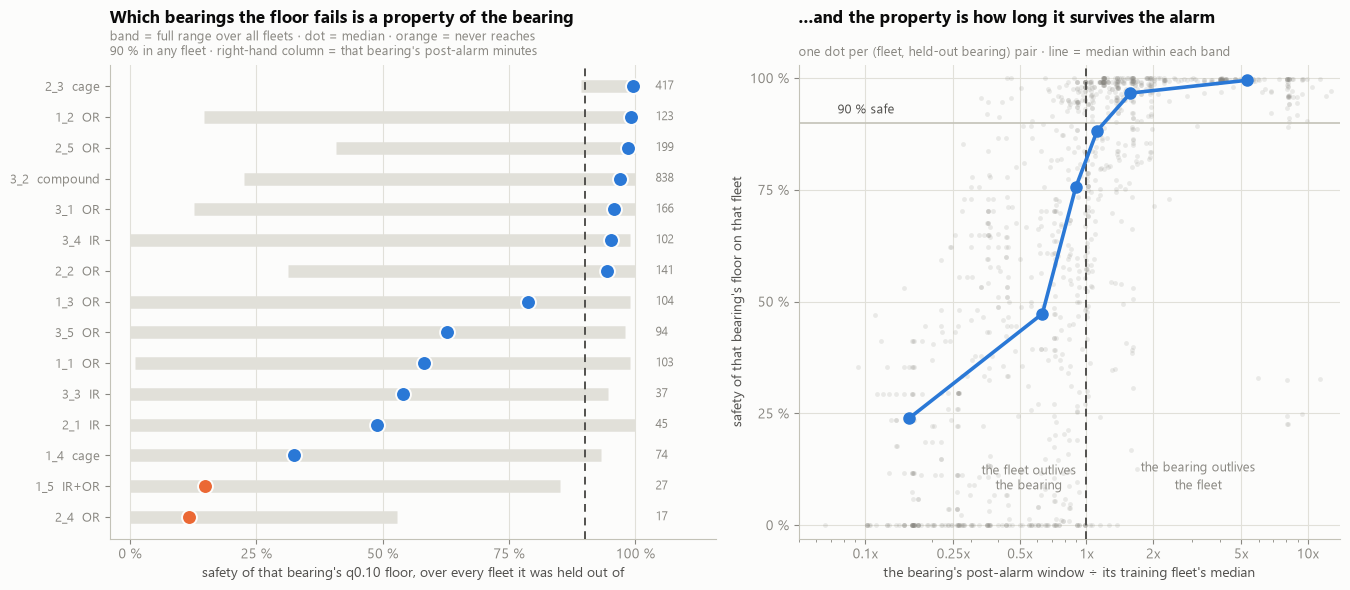

unit         fault      post   life   median     min     max  fleets
Bearing2_4   OR           17     42    11.8%    0.0%   52.9%      80
Bearing1_5   IR+OR        27     52    14.8%    0.0%   85.2%      73
Bearing1_4   cage         74    122    32.4%    0.0%   93.2%      70
Bearing2_1   IR           45    491    48.9%    0.0%  100.0%      75
Bearing3_3   IR           37    371    54.1%    0.0%   94.6%      67
Bearing1_1   OR          103    123    58.3%    1.0%   99.0%      72
Bearing3_5   OR           94    114    62.8%    0.0%   97.9%      75
Bearing1_3   OR          104    158    78.8%    0.0%   99.0%      67
Bearing2_2   OR          141    161    94.3%   31.2%  100.0%      73
Bearing3_4   IR          102   1515    95.1%    0.0%   99.0%      70
Bearing3_1   OR          166   2538    95.8%   12.7%  100.0%      71
Bearing3_2   compound    838   2496    97.0%   22.6%   99.9%      61
Bearing2_5   OR          199    339    98.5%   40.7%  100.0%      63
Bearing1_2   OR          123    16

In [3]:
POSTW = base.groupby("unit")["post_n"].first().to_dict()
FLEET = {}
for (n, s), g in base.groupby(["n", "subset"]):
    held = set(g["unit"])
    FLEET[(n, s)] = float(np.median([v for u, v in POSTW.items() if u not in held]))
F = base[base["scheme"] == "forest"].copy()
F["ratio"] = F["post_n"] / [FLEET[(n, s)] for n, s in zip(F["n"], F["subset"])]

pu = (F.groupby(["unit", "fault"])
      .agg(med=("safety", "median"), lo=("safety", "min"), hi=("safety", "max"),
           life=("life", "first"), post=("post_n", "first"),
           folds=("safety", "size")).reset_index().sort_values("med"))

fig, (axa, axb) = plt.subplots(1, 2, figsize=(13.6, 6.0),
                               gridspec_kw=dict(width_ratios=[1.12, 1]))

for i, (_, r) in enumerate(pu.iterrows()):
    axa.plot([100 * r["lo"], 100 * r["hi"]], [i, i], color=GRID, lw=9,
             solid_capstyle="butt", zorder=2)
    axa.scatter([100 * r["med"]], [i], s=115, zorder=5, edgecolor=SURFACE, linewidth=1.4,
                color=C_ORANGE if r["hi"] < 0.90 else C_BLUE)
    axa.annotate(f"{r['post']:.0f}", (104, i), fontsize=8.6, color=MUTED, va="center")
axa.axvline(90, color=INK2, lw=1.4, ls=(0, (4, 3)), zorder=4)
axa.set_yticks(range(len(pu)))
axa.set_yticklabels([f"{r['unit'].replace('Bearing', '')}  {r['fault']}"
                     for _, r in pu.iterrows()], fontsize=9.3)
axa.set_xlim(-4, 116)
axa.set_xticks(range(0, 101, 25))
axa.set_xticklabels([f"{v} %" for v in range(0, 101, 25)])
axa.set_xlabel("safety of that bearing's q0.10 floor, over every fleet it was held out of")
axa.set_title("Which bearings the floor fails is a property of the bearing", loc="left",
              fontsize=12.5, fontweight="bold", pad=30)
axa.annotate("band = full range over all fleets · dot = median · orange = never reaches\n"
             "90 % in any fleet · right-hand column = that bearing's post-alarm minutes",
             xy=(0, 1.012), xycoords="axes fraction", fontsize=9.3, color=MUTED, va="bottom")
axa.grid(axis="y", visible=False)

axb.scatter(F["ratio"], 100 * F["safety"], s=12, color=MUTED, alpha=0.16, zorder=2,
            linewidths=0)
EDGES = [0, 0.5, 0.8, 1.0, 1.25, 2.0, 100]
mids, meds = [], []
for lo, hi in zip(EDGES[:-1], EDGES[1:]):
    s = F[(F["ratio"] >= lo) & (F["ratio"] < hi)]
    if len(s):
        mids.append(np.sqrt(max(lo, 0.05) * min(hi, 14)))
        meds.append(100 * s["safety"].median())
axb.plot(mids, meds, color=C_BLUE, lw=2.6, marker="o", ms=8, zorder=5)
axb.axvline(1.0, color=INK2, lw=1.4, ls=(0, (4, 3)), zorder=4)
axb.axhline(90, color=BASE, lw=1.2, zorder=3)
axb.annotate("the fleet outlives\nthe bearing", (0.55, 8), fontsize=9, color=MUTED,
             ha="center", linespacing=1.4)
axb.annotate("the bearing outlives\nthe fleet", (3.2, 8), fontsize=9, color=MUTED,
             ha="center", linespacing=1.4)
axb.annotate("90 % safe", (0.075, 91.5), fontsize=9, color=INK2, va="bottom")
axb.set_xscale("log")
axb.set_xlim(0.05, 14)
axb.set_xticks([0.1, 0.25, 0.5, 1, 2, 5, 10])
axb.set_xticklabels(["0.1x", "0.25x", "0.5x", "1x", "2x", "5x", "10x"])
axb.set_ylim(-3, 103)
axb.set_yticks(range(0, 101, 25))
axb.set_yticklabels([f"{v} %" for v in range(0, 101, 25)])
axb.set_xlabel("the bearing's post-alarm window ÷ its training fleet's median")
axb.set_ylabel("safety of that bearing's floor on that fleet")
axb.set_title("...and the property is how long it survives the alarm", loc="left",
              fontsize=12.5, fontweight="bold", pad=30)
axb.annotate("one dot per (fleet, held-out bearing) pair · line = median within each band",
             xy=(0, 1.012), xycoords="axes fraction", fontsize=9.3, color=MUTED, va="bottom")
plt.tight_layout()
plt.show()

print(f"{'unit':12s} {'fault':9s} {'post':>5} {'life':>6} {'median':>8} {'min':>7} {'max':>7}"
      f" {'fleets':>7}")
for _, r in pu.iterrows():
    print(f"{r['unit']:12s} {r['fault']:9s} {r['post']:5.0f} {r['life']:6.0f} "
          f"{r['med']:8.1%} {r['lo']:7.1%} {r['hi']:7.1%} {r['folds']:7.0f}")
never, alw = pu[pu["hi"] < 0.90], pu[pu["lo"] >= 0.90]
print(f"\nnever 90 % safe in ANY fleet : {len(never)}/{len(pu)}  "
      f"({', '.join(never['unit'].str.replace('Bearing', ''))})")
print(f"90 % safe in EVERY fleet     : {len(alw)}/{len(pu)}"
      + (f"  (closest: {pu.loc[pu['lo'].idxmax(), 'unit'].replace('Bearing', '')} "
         f"at {pu['lo'].max():.1%})" if not len(alw) else ""))
for lab, col in (("post-alarm window", "post"), ("total life", "life")):
    rho, p = spearmanr(pu[col], pu["med"])
    print(f"per-unit median safety vs {lab:18s} rho = {rho:+.3f}  p = {p:.2e}")

print("\nsafety by how the bearing compares with its training fleet:")
for lo, hi in zip(EDGES[:-1], EDGES[1:]):
    s = F[(F["ratio"] >= lo) & (F["ratio"] < hi)]
    if len(s):
        print(f"  {lo:5.2f}-{hi:6.2f}x  n={len(s):4d}  median safety {s['safety'].median():6.1%}"
              f"   clear90 {(s['safety'] >= 0.90).mean():6.1%}")
rho, p = spearmanr(F["ratio"], F["safety"])
print(f"  overall rho = {rho:+.3f}, p = {p:.2e}  ({len(F)} fleet-bearing pairs)")
wi = [spearmanr(g["ratio"], g["safety"])[0] for _, g in F.groupby("unit")
      if g["ratio"].nunique() > 5]
print(f"  within-bearing, across the fleets it faced: {sum(x > 0 for x in wi)}/{len(wi)} "
      f"positive, median rho = {np.median(wi):+.3f}")

The failure is a property of the bearing, and the property is how long the bearing survives its own alarm. Per-unit median safety correlates with the post-alarm window at rho = +0.904 (p = 3.9 × 10⁻⁶), against +0.652 for total lifetime, so it is the post-alarm window and not the age that decides it. Two of fifteen bearings never reach 90 % safety in any fleet at all: Bearing2_4 (17 post-alarm minutes) and Bearing1_5 (27). These are the two shortest windows in the set, and no training fleet in the sweep rescues either.

The converse should be quoted beside it: not one of the fifteen is 90 % safe in every fleet. The closest is Bearing2_3 at 89.2 %. Every bearing here has a training fleet against which its floor breaks.

The right panel shows the mechanism, a threshold at parity. Safety tracks the ratio of the bearing's post-alarm window to its training fleet's median at rho = +0.757 (p ≈ 10⁻¹⁹⁷ over 1055 fleet–bearing pairs), and the bands are:

| bearing's window ÷ fleet median | median safety | share clearing 90 % |
|---|---|---|
| below 0.5× | 23.9 % | 2.7 % |
| 0.5–0.8× | 47.3 % | 8.5 % |
| 0.8–1.0× | 75.5 % | 38.6 % |
| 1.0–1.25× | 88.2 % | 49.3 % |
| 1.25–2× | 96.6 % | 71.1 % |
| above 2× | 99.5 % | 92.9 % |

The floor holds for a bearing roughly when the fleet does not outlive it. That is not merely definitional. Short-lived units being harder is expected, since a model trained on long lives will overshoot a short one, but the size of the drop is not expected, and neither is the part that holds the bearing fixed: within a single bearing, across the different fleets it was scored against, 13 of 15 have a positive correlation (median rho = +0.335). The same bearing's floor becomes safer or breaks depending on the fleet it is compared with, which is the half of the effect that a between-unit explanation cannot account for.

This explains the inverted confound. Adding snapshots at a fixed fleet size means adding the long bearings (the three longest supply 71 % of this dataset), which raises the fleet's median post-alarm window and pushes every short unit further into the low-safety bands. Growing the fleet does both things at once, and they cancel. Fleet size is the wrong axis; the fleet's lifetime composition is the right one.

## Consequences for the floor and for additional data

The open item asked how many bearings a floor needs. The question has no numerical answer, because the count does not determine safety.

"At least n minutes" can be said to an engineer when the training fleet contains bearings that fail as fast as the one in front of you. Adding bearings that do not fail that fast cannot make it safe.

That specifies what additional data would have to contain: short post-alarm windows, at or below the regime of the unit being protected. More of what XJTU-SY already has in abundance would move none of these curves.

### Findings

1. The harness reproduces notebook 17 exactly: 91 % median safety, 63 % give-up, 6 of 11 race units clearing 90 %. The curve is anchored to a published result at its right-hand end.
2. Fleet size does not raise the per-unit promise. 44.9 % → 53.3 % of bearings clearing 90 % safety as the fleet goes 4 → 14, rho = +0.323, p = 0.33. The whole safety–give-up frontier for four bearings sits on top of the one for fourteen.
3. The floor still carries information. The permuted control collapses to 0–7.8 %, and the forest beats the lifetime-prior control at all eleven fleet sizes, with a give-up of its own (n=14: 91.0 % safe / 53.3 % clearing at 63.0 % give-up, against 76.7 % / 13.3 % at 53.4 %).
4. More snapshots make it worse. Safety against bearing count is +0.052; against snapshot count it is −0.207, falling to −0.444 at a fixed fleet size of twelve.
5. Two of fifteen bearings are never 90 % safe in any fleet: Bearing2_4 (17 post-alarm minutes) and Bearing1_5 (27), the two shortest windows in the set.
6. None of the fifteen is 90 % safe in every fleet. The closest is Bearing2_3 at 89.2 %. Every bearing has a fleet against which its floor breaks.
7. Safety is set by the mismatch in lifetime, with a threshold at parity. rho = +0.757 over 1055 fleet–bearing pairs; the 90 %-clearing share runs from 2.7 % below 0.5× to 92.9 % above 2×, crossing near 1×. Per unit, median safety tracks the post-alarm window at rho = +0.904, better than total lifetime at +0.652.
8. The effect survives holding the bearing fixed. Within a single bearing, across the fleets it faced, 13 of 15 correlations are positive (median rho = +0.335), so this is not only short units being intrinsically harder.